# Index Breadth Momentum Study

## Setup

In [1]:
# imports
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import talib
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# one chart style everywhere
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "font.size": 10,
})

In [2]:
# load the constituent table and the SPY benchmark from the release

spy_consti = pd.read_parquet('https://github.com/rlp-jym/zoomcamp-sma-cohort-2026/releases/download/v0.1-data/sp500_constituents_daily.parquet')
spy = pd.read_parquet('https://github.com/rlp-jym/zoomcamp-sma-cohort-2026/releases/download/v0.1-data/SPY.parquet')

In [3]:
# inspect the constituent table: schema, dtypes, memory

print(spy_consti.info())

spy_consti.head().T

<class 'pandas.DataFrame'>
RangeIndex: 1566806 entries, 0 to 1566805
Data columns (total 17 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   date               1566806 non-null  datetime64[ns]
 1   index_name         1566806 non-null  str           
 2   issuer_id          1566806 non-null  string        
 3   name               1566806 non-null  string        
 4   ticker             1365397 non-null  str           
 5   open               1337624 non-null  float64       
 6   high               1337624 non-null  float64       
 7   low                1337624 non-null  float64       
 8   close              1337624 non-null  float64       
 9   adj_close          1337624 non-null  float64       
 10  volume             1337624 non-null  float64       
 11  index_weight       1566806 non-null  float64       
 12  coverage_names     1566806 non-null  float64       
 13  coverage_weight    1566806 non-null  f

,0,1,2,3,4
date,2014-06-02 00:00:00,2014-06-02 00:00:00,2014-06-02 00:00:00,2014-06-02 00:00:00,2014-06-02 00:00:00
index_name,SP500,SP500,SP500,SP500,SP500
issuer_id,apple,exxon mobil,google,microsoft,johnson and johnson
name,"Apple, Inc",Exxon Mobil Corp,"Google, Inc. (Class A)",Microsoft Corp,Johnson & Johnson
ticker,AAPL,XOM,NaN,MSFT,JNJ
open,22.64143,100.529999,NaN,40.950001,101.540001
high,22.672501,100.879997,NaN,41.09,102.260002
low,22.232143,99.669998,NaN,40.68,101.010002
close,22.451786,99.940002,NaN,40.790001,102.169998
adj_close,19.656939,59.890575,NaN,34.12075,73.061264


In [4]:
# inspect the SPY benchmark table

print(spy.info())

spy.head().T

<class 'pandas.DataFrame'>
RangeIndex: 3136 entries, 0 to 3135
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       3136 non-null   datetime64[ms]
 1   open       3136 non-null   float64       
 2   high       3136 non-null   float64       
 3   low        3136 non-null   float64       
 4   close      3136 non-null   float64       
 5   adj_close  3136 non-null   float64       
 6   volume     3136 non-null   int64         
dtypes: datetime64[ms](1), float64(5), int64(1)
memory usage: 171.6 KB
None


,0,1,2,3,4
date,2014-06-02 00:00:00,2014-06-03 00:00:00,2014-06-04 00:00:00,2014-06-05 00:00:00,2014-06-06 00:00:00
open,192.949997,192.429993,192.470001,193.410004,194.869995
high,192.990005,192.899994,193.300003,194.649994,195.429993
low,191.970001,192.25,192.270004,192.699997,194.779999
close,192.899994,192.800003,193.190002,194.449997,195.380005
adj_close,156.585037,156.503815,156.820465,157.843201,158.598129
volume,64656000,65047000,55529000,92103000,78696000


## Processing

In [5]:
# indicator settings: window and lookback periods


periods = [(1, '1d'), (5, '5d'), (20, '20d'), (60, '60d')] # representing weekly, monthly, quarterly

### Index (SPY)

In [6]:
# null check on the index

# spy.isnull().sum()

In [7]:
# SPY: turnover, forward returns (close, max, min), SMA, ATR, RSI

spy['turnover_value'] = (spy.close * spy.volume).astype('int64')

for n, tf in periods:
    spy[f'chg_{tf}'] = ((spy.close.shift(-n) / spy.close) - 1) * 100
    spy[f'chg_{tf}_max'] = ((spy.high.rolling(n).max().shift(-n) / spy.close) - 1) * 100
    spy[f'chg_{tf}_min'] = ((spy.low.rolling(n).min().shift(-n) / spy.close) - 1) * 100
    spy[f'atr_{tf}'] = talib.ATR(spy.high.values, spy.low.values, spy.close.values, timeperiod=n)
    spy[f'sma_{tf}'] = talib.SMA(spy.close.values, timeperiod=n)
    spy[f'atr_{tf}_pct'] = spy[f'atr_{tf}'] / spy.close * 100
    if n > 1:  
        spy[f'rsi_{tf}'] = talib.RSI(spy.close.values, timeperiod=n) # TA-Lib RSI needs period >= 2
        spy[f'rel_sma_{tf}'] = ((spy.close / spy[f'sma_{tf}']) - 1) * 100 # SPY specific indicator

# distance to SMA in units of the 20d average true range
# 20d ATR is stable and independent of the horizon's own noise
# use for cut/sizing: stop at -1x of 20d ATR
for n, tf in periods:
    if n == 1:
        continue
    spy[f"rel_sma_{tf}_atr"] = spy[f"rel_sma_{tf}"] / spy["atr_20d_pct"]

In [8]:
# preview the enriched spy

# spy.iloc[60].T

### Constituents

Null ticker and ohlc values - cannot match because of missing CUSIP before 2019 (list issuer names only); and names that got delisted or renamed has no lookup entry and stays unresolved.
- 15 rows cleared on purpose. Ticker reuse (IR, CB, AVGO) and a share-class clash (UAA Class C) failed price reconciliation; the ticker is blanked and the row kept (see config/exclusions.csv).
- These rows stay in the table because they carry index weight; removing them would shrink the denominator. coverage_names / coverage_weight measure the shortfall, and weighted_ok / equal_weight_ok gate the readings.

In [9]:
# null check on the constituent table
# ticker is null for ~1,155 issuers: no CUSIP before 2019 and no name match (delisted or renamed); OHLC null where no price

spy_consti.isnull().sum()

date                      0
index_name                0
issuer_id                 0
name                      0
ticker               201409
open                 229182
high                 229182
low                  229182
close                229182
adj_close            229182
volume               229182
index_weight              0
coverage_names            0
coverage_weight           0
weighted_ok               0
equal_weight_ok           0
days_since_filing         0
dtype: int64

In [10]:
# normalise string columns to lowercase snake_case

for c in list(spy_consti.select_dtypes('str').columns):
    spy_consti[c] = spy_consti[c].str.lower().str.replace(' ', '_')    

In [11]:
# per-issuer indicators (the same as spy), joined back once as a single reshape

close_wide = spy_consti.pivot(index="date", columns="issuer_id", values="close")
high_wide = spy_consti.pivot(index="date", columns="issuer_id", values="high")
low_wide = spy_consti.pivot(index="date", columns="issuer_id", values="low")

wide = {}

for n, tf in periods:
    sma, rsi, atr = {}, {}, {}
    for col in close_wide.columns:
        s = close_wide[col].dropna()
        idx = s.index
        sma[col] = pd.Series(talib.SMA(s.values, n), index=idx)
        if n > 1:  # TA-Lib RSI needs period >= 2
            rsi[col] = pd.Series(talib.RSI(s.values, n), index=idx)
        atr[col] = pd.Series(talib.ATR(high_wide[col].reindex(idx).values,
                                       low_wide[col].reindex(idx).values,
                                       s.values, n), index=idx)

    sma_df = pd.DataFrame(sma).reindex(index=close_wide.index, columns=close_wide.columns)
    atr_df = pd.DataFrame(atr).reindex(index=close_wide.index, columns=close_wide.columns)

    wide[f"sma_{tf}"] = sma_df
    wide[f"rel_sma_{tf}"] = (close_wide / sma_df - 1) * 100
    wide[f"atr_{tf}"] = atr_df
    wide[f"atr_{tf}_pct"] = atr_df / close_wide * 100
    wide[f"chg_{tf}"] = ((close_wide.shift(-n) / close_wide) - 1) * 100
    wide[f"chg_{tf}_max"] = ((high_wide.rolling(n).max().shift(-n) / close_wide) - 1) * 100
    wide[f"chg_{tf}_min"] = ((low_wide.rolling(n).min().shift(-n) / close_wide) - 1) * 100
    wide[f"ret_{tf}"] = close_wide.pct_change(n) * 100
    if rsi:
        wide[f"rsi_{tf}"] = pd.DataFrame(rsi).reindex(index=close_wide.index, columns=close_wide.columns)

# distance to SMA in units of the 20d average true range
for n, tf in periods:
    if n == 1:
        continue
    wide[f"rel_sma_{tf}_atr"] = wide[f"rel_sma_{tf}"] / wide["atr_20d_pct"]

# 13w / 26w / 52w extremes
for label, window in {"13w": 65, "26w": 130, "52w": 252}.items():
    hi = close_wide.rolling(window, min_periods=window).max()
    lo = close_wide.rolling(window, min_periods=window).min()
    wide[f"high_{label}"] = (close_wide >= hi).astype(float).where(hi.notna())
    wide[f"low_{label}"] = (close_wide <= lo).astype(float).where(lo.notna())

# one reshape: (date, issuer) x field
flat = pd.MultiIndex.from_product([close_wide.index, close_wide.columns], names=["date", "issuer_id"])
long = pd.DataFrame({k: v.to_numpy().ravel() for k, v in wide.items()}, index=flat)

spy_consti = spy_consti.drop(columns=[c for c in wide if c in spy_consti.columns], errors="ignore")
spy_consti = spy_consti.set_index(["date", "issuer_id"]).join(long).reset_index()

# dollar volume per issuer, used for turnover breadth
spy_consti["turnover_value"] = spy_consti.volume * spy_consti.close

In [12]:
# preview the enriched table (nvda sample)

# spy_consti[spy_consti.ticker == 'nvda'].iloc[60].T

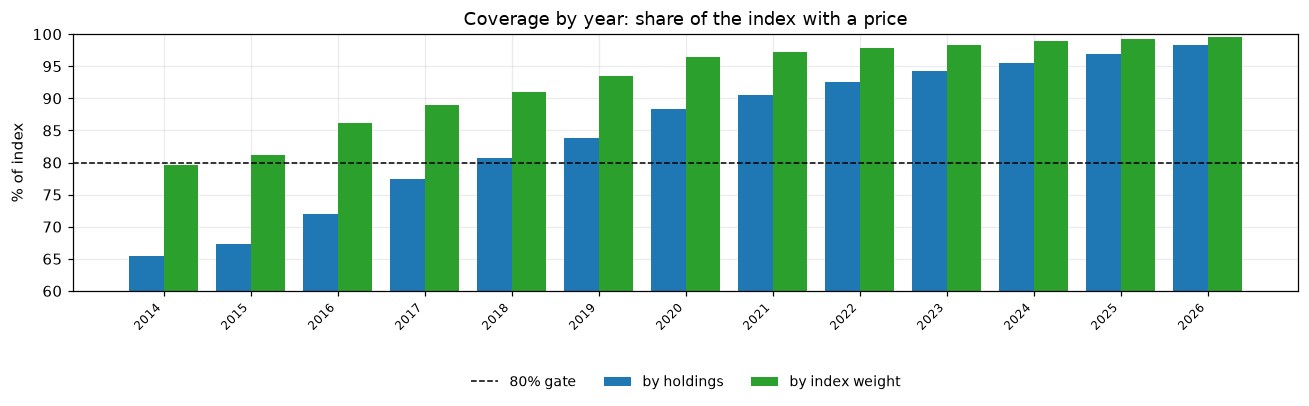

In [13]:
# coverage by year: share of the index composite that still has a price
# the 80% gate decides the study window: weighted from 2014-12-01, equal-weight from 2018-05-29
cov = (spy_consti
       .groupby("date")[["coverage_names", "coverage_weight", "weighted_ok", "equal_weight_ok"]]
       .first())
cov_y = cov.resample("YE").mean()

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(cov_y))
ax.bar(x - 0.2, cov_y["coverage_names"], width=0.4, color="tab:blue", label="by holdings")
ax.bar(x + 0.2, cov_y["coverage_weight"], width=0.4, color="tab:green", label="by index weight")
ax.axhline(80, color="black", ls="--", lw=1, label="80% gate")
ax.set_xticks(x)
ax.set_xticklabels([d.year for d in cov_y.index], rotation=45, ha="right", fontsize=8)
ax.set_ylim(60, 100)
ax.set_ylabel("% of index")
ax.set_title("Coverage by year: share of the index with a price")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3,
          fontsize=9, frameon=False)

fig.tight_layout()
Path("docs").mkdir(exist_ok=True)
fig.savefig("docs/coverage_by_year.png", dpi=150, bbox_inches="tight")

In [14]:
spy_gated = spy[spy.date >= '2015-01-01'].copy()
spy_consti_gated = spy_consti[spy_consti.date >= '2015-01-01'].copy()

In [15]:
# market breadth: weighted share of the index trading above each SMA

spy_breadth = pd.DataFrame(index=sorted(spy_consti_gated.date.unique()))
spy_breadth.index.name = "date"

# 1d SMA equals the close itself, so only multi-day averages define breadth

for tf in [tf for n, tf in periods if n > 1]:
    above = (spy_consti_gated.close > spy_consti_gated[f"sma_{tf}"]).astype(float)
    above = above.where(spy_consti_gated[f"sma_{tf}"].notna() & spy_consti_gated.close.notna())

    tmp = pd.DataFrame({
        "x": above * spy_consti_gated.index_weight,
        "w": spy_consti_gated.index_weight.where(above.notna()),
    })
    agg = tmp.groupby(spy_consti_gated.date).sum()
    spy_breadth[f"breadth_sma_{tf}"] = agg.x / agg.w * 100

    # advance/decline breadth: weighted share with a positive trailing return
    up = (spy_consti_gated[f"ret_{tf}"] > 0).astype(float).where(spy_consti_gated[f"ret_{tf}"].notna())
    tmp = pd.DataFrame({
        "x": up * spy_consti_gated.index_weight,
        "w": spy_consti_gated.index_weight.where(up.notna()),
    })
    agg_ad = tmp.groupby(spy_consti_gated.date).sum()
    spy_breadth[f"breadth_adv_dec_{tf}"] = agg_ad.x / agg_ad.w * 100

    # overbought / oversold breadth: weighted share with RSI above 70 or below 30
    for label, flag in [("rsi70", spy_consti_gated[f"rsi_{tf}"] > 70),
                        ("rsi30", spy_consti_gated[f"rsi_{tf}"] < 30)]:
        hit = flag.astype(float).where(spy_consti_gated[f"rsi_{tf}"].notna())
        tmp = pd.DataFrame({
            "x": hit * spy_consti_gated.index_weight,
            "w": spy_consti_gated.index_weight.where(hit.notna()),
        })
        agg_rsi = tmp.groupby(spy_consti_gated.date).sum()
        spy_breadth[f"breadth_{label}_{tf}"] = agg_rsi.x / agg_rsi.w * 100

# new highs / lows: weighted share at a 52-week extreme
for name in ("high_13w", "low_13w", "high_26w", "low_26w", "high_52w", "low_52w"):
    hit = spy_consti_gated[name].where(spy_consti_gated[name].notna())
    tmp = pd.DataFrame({
        "x": hit.fillna(0) * spy_consti_gated.index_weight,
        "w": spy_consti_gated.index_weight.where(hit.notna()),
    })
    agg_hl = tmp.groupby(spy_consti_gated.date).sum()
    spy_breadth[f"breadth_{name}"] = agg_hl.x / agg_hl.w * 100

# breadth momentum: 5-day change in the share above each average
for tf in ("5d", "20d", "60d"):
    spy_breadth[f"breadth_sma_{tf}_chg_5d"] = spy_breadth[f"breadth_sma_{tf}"].diff(5)

# activity: index-wide dollar volume relative to its 60-day norm
turnover_tot = spy_consti_gated.groupby("date")["turnover_value"].sum()
spy_breadth["breadth_turnover_rel_60d"] = turnover_tot / turnover_tot.rolling(60).mean()

spy_breadth.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2987 entries, 2015-01-02 to 2026-11-17
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   breadth_sma_5d            2987 non-null   float64
 1   breadth_adv_dec_5d        2987 non-null   float64
 2   breadth_rsi70_5d          2987 non-null   float64
 3   breadth_rsi30_5d          2987 non-null   float64
 4   breadth_sma_20d           2987 non-null   float64
 5   breadth_adv_dec_20d       2987 non-null   float64
 6   breadth_rsi70_20d         2987 non-null   float64
 7   breadth_rsi30_20d         2987 non-null   float64
 8   breadth_sma_60d           2987 non-null   float64
 9   breadth_adv_dec_60d       2987 non-null   float64
 10  breadth_rsi70_60d         2987 non-null   float64
 11  breadth_rsi30_60d         2987 non-null   float64
 12  breadth_high_13w          2987 non-null   float64
 13  breadth_low_13w           2987 non-null   float64
 14  b

## Modelling

In [16]:
RANDOM_STATE = 9 # my lucky number
BENCHMARK_CAGR = 0.07 # real alternative, i.e. 5-7% gross CAGR
LEVERAGE = 1.0 # 1.0 = no leverage; scales return and drawdown
RISK_FREE_RATE = 0.035 # used ONLY by Sharpe and Sortino; CAGR is BENCHMARK_CAGR
FEE_PER_TRADE_R = 0.005 # ~3bps round trip on ~10% notional, charged per trade
# tax is NOT deducted: both the strategy and the 7% benchmark are pre-tax
# the comparison is both gross; skipping since treatment depends on residency and instrument

In [17]:
# merge the breadth readings with the SPY benchmark: one row per trading day

df = spy.merge(spy_breadth, left_on="date", right_index=True, how="inner")

In [18]:
# volatility-adjusted forward return: forward move normalized in multiples of 20d ATR
# 20d ATR serves as the risk unit: cut sits at -1 unit and sizing scales with it
# RR col as `risk:reward` ratio

for _, tf in periods:
    df[f"rr_{tf}"] = df[f"chg_{tf}"] / df["atr_20d_pct"]
    df[f"rr_{tf}_max"] = df[f"chg_{tf}_max"] / df["atr_20d_pct"]
    df[f"rr_{tf}_min"] = df[f"chg_{tf}_min"] / df["atr_20d_pct"]

### 5-day window

In [19]:
# constituent medians: distance to SMA, RSI and ATR% per issuer, median across issuers

close_wide = spy_consti.pivot(index="date", columns="issuer_id", values="close")

consti_med = pd.DataFrame(index=close_wide.index)
for n, tf in periods:
    if n == 1:
        continue
    rel_wide = spy_consti.pivot(index="date", columns="issuer_id", values=f"rel_sma_{tf}")
    rsi_wide = spy_consti.pivot(index="date", columns="issuer_id", values=f"rsi_{tf}")
    atr_wide = spy_consti.pivot(index="date", columns="issuer_id", values=f"atr_{tf}_pct")

    consti_med[f"med_rel_sma_{tf}"] = rel_wide.median(axis=1)
    consti_med[f"iqr_rel_sma_{tf}"] = rel_wide.quantile(0.75, axis=1) - rel_wide.quantile(0.25, axis=1)
    rel_sma_atr_wide = spy_consti.pivot(index="date", columns="issuer_id", values=f"rel_sma_{tf}_atr")
    consti_med[f"med_rel_sma_{tf}_atr"] = rel_sma_atr_wide.median(axis=1)
    consti_med[f"med_rsi_{tf}"] = rsi_wide.median(axis=1)
    consti_med[f"med_atr_pct_{tf}"] = atr_wide.median(axis=1)

print(consti_med.shape)
print(consti_med.isna().sum().to_string())

(3136, 15)
med_rel_sma_5d          4
iqr_rel_sma_5d          4
med_rel_sma_5d_atr     20
med_rsi_5d              5
med_atr_pct_5d          5
med_rel_sma_20d        19
iqr_rel_sma_20d        19
med_rel_sma_20d_atr    20
med_rsi_20d            20
med_atr_pct_20d        20
med_rel_sma_60d        59
iqr_rel_sma_60d        59
med_rel_sma_60d_atr    59
med_rsi_60d            60
med_atr_pct_60d        60


In [20]:
# 5-day study: modelling frame (target = forward 5-day move in ATR units)

df_5d = df.sort_values("date").reset_index(drop=True).copy()
df_5d = df_5d.merge(consti_med, left_on="date", right_index=True, how="left")

# excluding breadth rsi 70/30 60d, less than 1% of dataset
FEATURES = ["breadth_sma_5d", "breadth_sma_20d", "breadth_sma_60d",
            "breadth_rsi70_5d", "breadth_rsi70_20d", # "breadth_rsi70_60d",
            "breadth_rsi30_5d", "breadth_rsi30_20d", # "breadth_rsi30_60d",
            "med_rel_sma_5d_atr", "med_rel_sma_20d_atr", "med_rel_sma_60d_atr",
            "med_rsi_5d", "med_rsi_20d", "med_rsi_60d",
            "med_atr_pct_5d", "med_atr_pct_20d", "med_atr_pct_60d",
            "breadth_adv_dec_5d", "breadth_adv_dec_20d", "breadth_adv_dec_60d",
            "breadth_high_13w", "breadth_low_13w",
            "breadth_high_26w", "breadth_low_26w",
            "breadth_high_52w", "breadth_low_52w",
            "breadth_sma_5d_chg_5d", "breadth_sma_20d_chg_5d", "breadth_sma_60d_chg_5d",
            "iqr_rel_sma_5d", "iqr_rel_sma_20d", "iqr_rel_sma_60d",
            "breadth_turnover_rel_60d",
            ]

TARGET = "rr_5d"

df_5d = df_5d.dropna(subset=[TARGET]).set_index("date")

# print(df_5d.shape)
# print(df_5d[FEATURES + [TARGET]].isna().sum().to_string())

# df_5d[FEATURES + [TARGET]].head().T

In [21]:
# final cleanup: keep rows with a target and every feature present
df_final = df_5d.dropna(subset=FEATURES + [TARGET]).copy()
df_final.index.name = "date"

print(df_final.shape, "| features:", len(FEATURES))
print("remaining nulls:", int(df_final[FEATURES + [TARGET]].isna().sum().sum()))
print(f"{df_final.index.min().date()} -> {df_final.index.max().date()}")
# df_final[FEATURES].head().T

(2880, 89) | features: 32
remaining nulls: 0
2015-06-01 -> 2026-11-10


In [22]:
# time-series split: 60% train, 20% validation, 20% test, in date order
n = len(df_final)
i_val, i_test = int(n * 0.6), int(n * 0.8)

df_final["split"] = "train"
df_final.iloc[i_val:i_test, df_final.columns.get_loc("split")] = "valid"
df_final.iloc[i_test:, df_final.columns.get_loc("split")] = "test"

print(df_final.groupby("split").agg(rows=("rr_5d", "size"),
                                    start=("rr_5d", lambda s: s.index.min().date()),
                                    end=("rr_5d", lambda s: s.index.max().date())))

       rows       start         end
split                              
test    576  2024-07-26  2026-11-10
train  1728  2015-06-01  2022-04-07
valid   576  2022-04-08  2024-07-25


#### Baseline

In [23]:
# shared KPI block: baseline and every model report the same fields
import numpy as np
KPI_HISTORY = {}   # one row per model, keyed by name so re-runs do not duplicate
RETURNS = {}       # daily return series per model, for equity and drawdown plots
def kpi_row(name, sig, frame, risk_per_r=0.01, hold=5, leverage=None, store=True):
    leverage = LEVERAGE if leverage is None else leverage
    long_days = frame.loc[sig, "rr_5d"]
    wins, losses = long_days[long_days > 0], long_days[long_days < 0]
    max_open = int(sig.rolling(hold).sum().max())
    risk_per_trade = 1 / max_open
    fees_r = len(long_days) * FEE_PER_TRADE_R          # one round trip per trade
    gross_r = long_days.sum()
    total_r_scaled = (gross_r - fees_r) * risk_per_trade
    total_return_pct = risk_per_r * leverage * total_r_scaled * 100
    gross_return_pct = risk_per_r * leverage * gross_r * risk_per_trade * 100
    income_margin_pct = 100 * total_return_pct / gross_return_pct

    # daily series: each position accrues 1/hold of its R per day, fee charged on entry
    daily_r = (sig.astype(float) * frame["rr_5d"] / hold).rolling(hold, min_periods=1).sum()
    ret = risk_per_r * leverage * risk_per_trade * (daily_r - sig.astype(float) * FEE_PER_TRADE_R)
    if store:
        RETURNS[name] = ret   # grid candidates are not kept
    equity = (1 + ret).cumprod()
    max_dd = (equity / equity.cummax() - 1).min()

    # risk-adjusted: excess over the risk-free rate, annualised by 252
    rf_daily = (1 + RISK_FREE_RATE) ** (1 / 252) - 1
    excess = ret - rf_daily
    vol_ann = ret.std() * np.sqrt(252) * 100
    sharpe = excess.mean() / excess.std() * np.sqrt(252)
    downside = excess[excess < 0].std()
    sortino = excess.mean() / downside * np.sqrt(252)
    years = len(frame) / 252
    cagr = ((1 + total_return_pct / 100) ** (1 / years) - 1) * 100
    return {
        "rule": name,                                      # what produced the signal
        "trades": len(long_days),                          # days the signal says be long
        "trade_share_%": round(100 * len(long_days) / len(frame), 1),  # % of days with an open trade
        "win_rate_%": round(100 * len(wins) / len(long_days), 1),  # % of long days ending positive
        "avg_win_r": round(wins.mean(), 3),                # mean R on winning days
        "avg_loss_r": round(losses.mean(), 3),             # mean R on losing days (negative)
        "profit_factor_x": round(wins.sum() / abs(losses.sum()), 2),  # total profit / total loss
        "expectancy_r": round(long_days.mean(), 3),        # expected R per long day
        "max_open_trades": max_open,                       # most positions open at once
        "max_risk_per_trade_%": round(100 * risk_per_trade, 1),  # % of one risk unit per position
        "leverage_x": leverage,                              # multiplier on return and drawdown
        "total_r": round(gross_r, 1),                      # raw sum (overlapping, not tradable)
        "fees_r": round(fees_r, 1),                        # total cost, in R units
        "income_margin_%": round(income_margin_pct, 1),     # net return / gross return
        "total_return_%": round(total_return_pct, 1),    # arithmetic % return
        "cagr_%": round(cagr, 2),                        # compounded annual return
        "max_drawdown_%": round(max_dd * 100, 2),        # worst peak-to-trough on the daily series
        "ann_vol_%": round(vol_ann, 2),                    # annualised volatility of the daily series
        "sharpe": round(sharpe, 2),                        # excess return per unit of total risk
        "sortino": round(sortino, 2),                      # excess return per unit of downside risk
    }

def add_kpi(name, sig, frame, **kw):
    """Score a signal, store it, and return the accumulated comparison table."""
    KPI_HISTORY[name] = kpi_row(name, sig, frame, **kw)
    return pd.DataFrame(list(KPI_HISTORY.values())).set_index("rule").T

In [24]:
# rule-of-thumb baseline: classic "buy when breadth is healthy", evaluated on VALIDATION
# kept as a documented attempt, and as the row every model has to beat
valid = df_final[df_final.split == "valid"]

sig_base = (
      (valid["breadth_sma_5d"]  > 50)
    & (valid["breadth_sma_20d"] > 50)
    & (valid["breadth_sma_60d"] > 50)
    )

kpi_base = add_kpi("baseline", sig_base, valid)
kpi_base

rule,baseline
trades,226.000
trade_share_%,39.200
win_rate_%,59.700
avg_win_r,1.111
avg_loss_r,-1.215
profit_factor_x,1.360
expectancy_r,0.174
max_open_trades,5.000
max_risk_per_trade_%,20.000
leverage_x,1.000


#### Decision Tree

In [25]:
# decision tree: fit on train, evaluate on validation, pre-tuning

train = df_final[df_final.split == "train"]
valid = df_final[df_final.split == "valid"]

tree = DecisionTreeRegressor(
    max_depth=3, 
    min_samples_leaf=50, 
    random_state=RANDOM_STATE
    )
tree.fit(train[FEATURES], train["rr_5d"])

sig_dt = pd.Series(tree.predict(valid[FEATURES]) > 0, index=valid.index)

kpi_dt = add_kpi("decision_tree", sig_dt, valid)
kpi_dt

rule,baseline,decision_tree
trades,226.000,541.000
trade_share_%,39.200,93.900
win_rate_%,59.700,58.000
avg_win_r,1.111,1.305
avg_loss_r,-1.215,-1.363
profit_factor_x,1.360,1.320
expectancy_r,0.174,0.186
max_open_trades,5.000,5.000
max_risk_per_trade_%,20.000,20.000
leverage_x,1.000,1.000


In [26]:
# decision tree tuning: depth and leaf size only, scored on validation

grid = {"max_depth": [2, 3, 4, 5, 6, 8],
        "min_samples_leaf": [10, 20, 50, 100, 200]}

rows = []
for depth, leaf in itertools.product(grid["max_depth"], grid["min_samples_leaf"]):
    model = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=RANDOM_STATE)
    model.fit(train[FEATURES], train["rr_5d"])
    s = pd.Series(model.predict(valid[FEATURES]) > 0, index=valid.index)
    rows.append(kpi_row(f"dt_d{depth}_l{leaf}", s, valid, store=False))

grid_dt = pd.DataFrame(rows)

# selection: best expectancy, but only among models that actually time the market
eligible = grid_dt[(grid_dt["trade_share_%"] <= 85) & (grid_dt["trades"] >= 100)]
print(f"{len(eligible)} of {len(grid_dt)} grid points eligible")
eligible.sort_values("expectancy_r", ascending=False).head(10).set_index("rule").round(3).T

16 of 30 grid points eligible


rule,dt_d8_l100,dt_d6_l10,dt_d6_l20,dt_d6_l100,dt_d3_l100,dt_d2_l200,dt_d3_l200,dt_d4_l200,dt_d8_l200,dt_d5_l200
trades,369.000,459.000,463.000,482.000,419.000,475.000,475.000,430.000,430.000,430.000
trade_share_%,64.100,79.700,80.400,83.700,72.700,82.500,82.500,74.700,74.700,74.700
win_rate_%,59.300,58.600,58.500,59.100,59.400,58.300,58.300,57.200,57.200,57.200
avg_win_r,1.274,1.268,1.267,1.232,1.178,1.232,1.232,1.270,1.270,1.270
avg_loss_r,-1.383,-1.338,-1.336,-1.334,-1.308,-1.324,-1.324,-1.340,-1.340,-1.340
profit_factor_x,1.350,1.340,1.340,1.340,1.320,1.300,1.300,1.270,1.270,1.270
expectancy_r,0.194,0.189,0.187,0.183,0.169,0.167,0.167,0.153,0.153,0.153
max_open_trades,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000
max_risk_per_trade_%,20.000,20.000,20.000,20.000,20.000,20.000,20.000,20.000,20.000,20.000
leverage_x,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


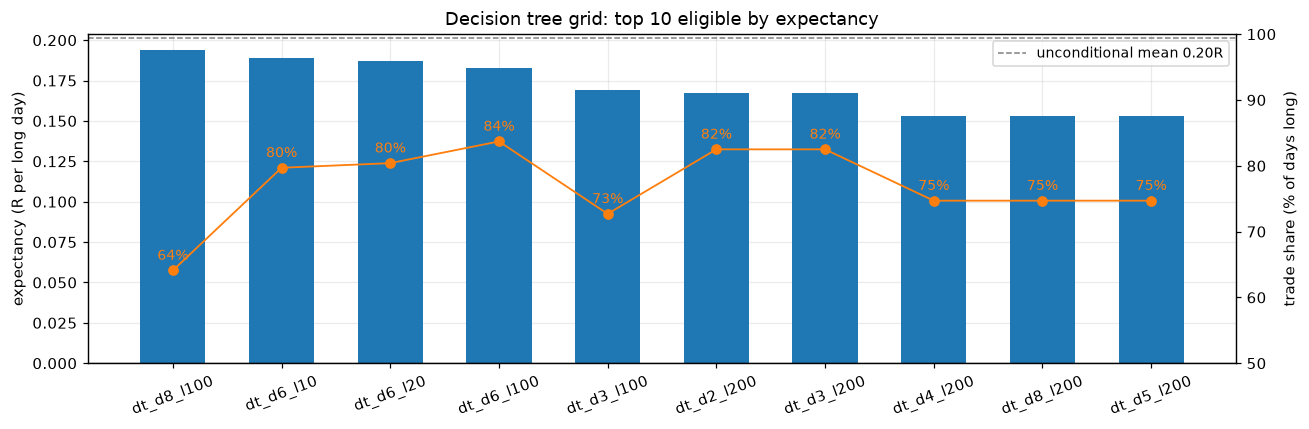

In [27]:
# top 10 eligible trees by validation expectancy, against the unconditional mean
top = eligible.sort_values("expectancy_r", ascending=False).head(10)
uncond = valid["rr_5d"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(top["rule"], top["expectancy_r"], width=0.6, color="tab:blue")
ax.axhline(uncond, color="grey", ls="--", lw=1,
           label=f"unconditional mean {uncond:.2f}R")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("expectancy (R per long day)")
ax.set_title("Decision tree grid: top 10 eligible by expectancy")
ax.tick_params(axis="x", rotation=20)

# secondary axis: how often each model is actually in the market (open exposure)
ax2 = ax.twinx()
ax2.plot(top["rule"], top["trade_share_%"], color="tab:orange", marker="o", lw=1.2,
         label="trade share")
for x, y in zip(top["rule"], top["trade_share_%"]):
    ax2.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 7),
                 ha="center", fontsize=9, color="tab:orange")
ax2.set_ylabel("trade share (% of days long)")
ax2.set_ylim(50, 100)
ax2.grid(False)

ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

In [28]:
# tuned decision tree: best eligible grid point, refit on train and scored on validation
best = eligible.sort_values("expectancy_r", ascending=False).iloc[0]
best_depth = int(best["rule"].split("_d")[1].split("_")[0])
best_leaf = int(best["rule"].split("_l")[1])
print(f"best grid point: {best['rule']}  depth={best_depth} leaf={best_leaf} expectancy={best['expectancy_r']}")

tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=RANDOM_STATE)
tree.fit(train[FEATURES], train["rr_5d"])

sig_dt = pd.Series(tree.predict(valid[FEATURES]) > 0, index=valid.index)

kpi_dt = add_kpi("decision_tree", sig_dt, valid)
kpi_dt

best grid point: dt_d8_l100  depth=8 leaf=100 expectancy=0.194


rule,baseline,decision_tree
trades,226.000,369.000
trade_share_%,39.200,64.100
win_rate_%,59.700,59.300
avg_win_r,1.111,1.274
avg_loss_r,-1.215,-1.383
profit_factor_x,1.360,1.350
expectancy_r,0.174,0.194
max_open_trades,5.000,5.000
max_risk_per_trade_%,20.000,20.000
leverage_x,1.000,1.000


breadth_rsi30_5d          0.191164
med_atr_pct_60d           0.155752
breadth_sma_5d_chg_5d     0.140055
breadth_high_52w          0.129496
breadth_low_52w           0.129392
med_rsi_60d               0.082731
breadth_rsi70_5d          0.046886
breadth_sma_60d           0.045614
breadth_sma_60d_chg_5d    0.032118
breadth_rsi70_20d         0.027938
dtype: float64

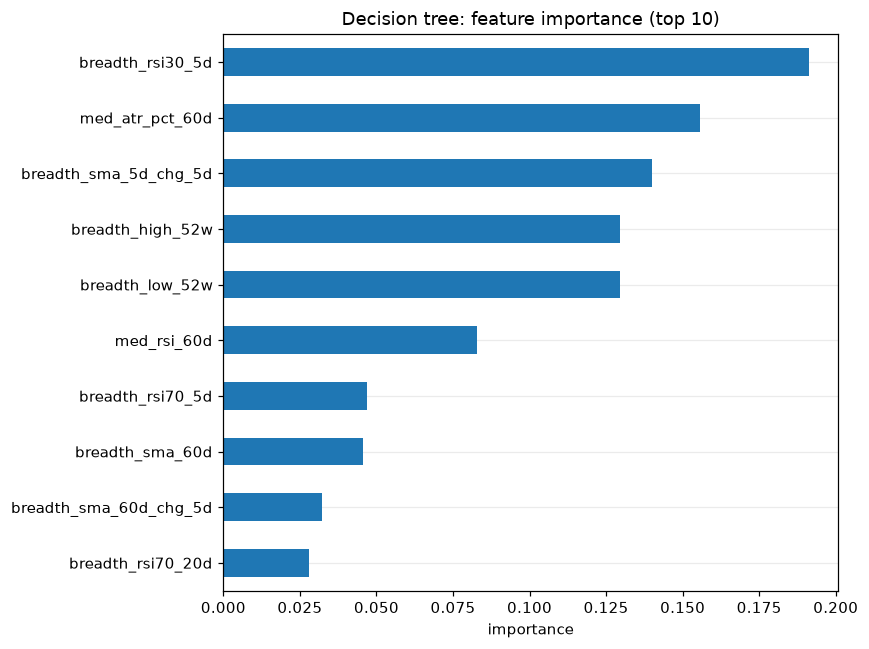

In [29]:
# decision tree feature importance
imp_dt = pd.Series(tree.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
imp_dt.head(10).iloc[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_title("Decision tree: feature importance (top 10)")
ax.set_xlabel("importance")
ax.grid(axis="x")

fig.tight_layout()

imp_dt.head(10)

#### Random Forest

In [30]:
# random forest: fit on train, evaluate on validation, pre-tuning

train = df_final[df_final.split == "train"]
valid = df_final[df_final.split == "valid"]

forest = RandomForestRegressor(
    max_depth=3, 
    min_samples_leaf=20,
    random_state=RANDOM_STATE,
    )
forest.fit(train[FEATURES], train["rr_5d"])

sig_rf = pd.Series(forest.predict(valid[FEATURES]) > 0, index=valid.index)

kpi_rf = add_kpi("random_forest", sig_rf, valid)
kpi_rf

rule,baseline,decision_tree,random_forest
trades,226.000,369.000,522.000
trade_share_%,39.200,64.100,90.600
win_rate_%,59.700,59.300,58.000
avg_win_r,1.111,1.274,1.302
avg_loss_r,-1.215,-1.383,-1.349
profit_factor_x,1.360,1.350,1.330
expectancy_r,0.174,0.194,0.190
max_open_trades,5.000,5.000,5.000
max_risk_per_trade_%,20.000,20.000,20.000
leverage_x,1.000,1.000,1.000


In [31]:
# random forest tuning: depth and leaf size only, scored on validation

grid = {"max_depth": [2, 3, 4, 5, 6, 8],
        "min_samples_leaf": [10, 20, 50, 100, 200]}

rows = []
for depth, leaf in itertools.product(grid["max_depth"], grid["min_samples_leaf"]):
    model = RandomForestRegressor(n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
                                  max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(train[FEATURES], train["rr_5d"])
    s = pd.Series(model.predict(valid[FEATURES]) > 0, index=valid.index)
    rows.append(kpi_row(f"rf_d{depth}_l{leaf}", s, valid, store=False))

grid_rf = pd.DataFrame(rows)

# selection: best expectancy, but only among models that actually time the market
eligible_rf = grid_rf[(grid_rf["trade_share_%"] <= 85) & (grid_rf["trades"] >= 100)]
print(f"{len(eligible_rf)} of {len(grid_rf)} grid points eligible")
eligible_rf.sort_values("expectancy_r", ascending=False).head(10).set_index("rule").round(3).T

16 of 30 grid points eligible


rule,rf_d8_l10,rf_d4_l20,rf_d6_l100,rf_d8_l20,rf_d8_l100,rf_d5_l100,rf_d6_l20,rf_d6_l50,rf_d6_l10,rf_d8_l50
trades,415.000,468.000,470.000,419.000,473.000,471.000,430.000,446.000,440.000,441.000
trade_share_%,72.000,81.200,81.600,72.700,82.100,81.800,74.700,77.400,76.400,76.600
win_rate_%,59.300,58.500,58.500,58.000,58.400,58.600,57.900,57.800,58.400,57.800
avg_win_r,1.255,1.287,1.263,1.282,1.267,1.256,1.276,1.283,1.260,1.289
avg_loss_r,-1.303,-1.358,-1.337,-1.334,-1.343,-1.343,-1.333,-1.340,-1.347,-1.355
profit_factor_x,1.400,1.340,1.330,1.330,1.320,1.320,1.320,1.310,1.310,1.300
expectancy_r,0.213,0.191,0.185,0.183,0.180,0.180,0.178,0.177,0.175,0.173
max_open_trades,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000
max_risk_per_trade_%,20.000,20.000,20.000,20.000,20.000,20.000,20.000,20.000,20.000,20.000
leverage_x,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


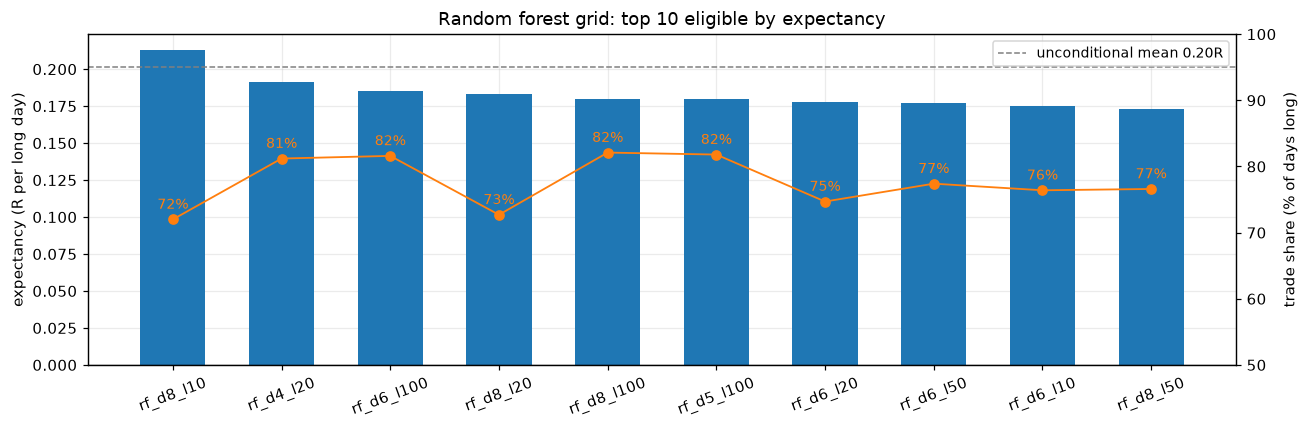

In [32]:
# top 10 eligible forests by validation expectancy, against the unconditional mean
top_rf = eligible_rf.sort_values("expectancy_r", ascending=False).head(10)
uncond = valid["rr_5d"].mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(top_rf["rule"], top_rf["expectancy_r"], width=0.6, color="tab:blue")
ax.axhline(uncond, color="grey", ls="--", lw=1,
           label=f"unconditional mean {uncond:.2f}R")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("expectancy (R per long day)")
ax.set_title("Random forest grid: top 10 eligible by expectancy")
ax.tick_params(axis="x", rotation=20)

# secondary axis: how often each model is actually in the market (open exposure)
ax2 = ax.twinx()
ax2.plot(top_rf["rule"], top_rf["trade_share_%"], color="tab:orange", marker="o", lw=1.2,
         label="trade share")
for x, y in zip(top_rf["rule"], top_rf["trade_share_%"]):
    ax2.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 7),
                 ha="center", fontsize=9, color="tab:orange")
ax2.set_ylabel("trade share (% of days long)")
ax2.set_ylim(50, 100)
ax2.grid(False)

ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

In [33]:
# tuned random forest: best eligible grid point, refit on train and scored on validation
best_rf = eligible_rf.sort_values("expectancy_r", ascending=False).iloc[0]
best_depth = int(best_rf["rule"].split("_d")[1].split("_")[0])
best_leaf = int(best_rf["rule"].split("_l")[1])
print(f"best grid point: {best_rf['rule']}  depth={best_depth} leaf={best_leaf} expectancy={best_rf['expectancy_r']}")

forest = RandomForestRegressor(n_estimators=300, max_depth=best_depth, min_samples_leaf=best_leaf,
                               max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)
forest.fit(train[FEATURES], train["rr_5d"])

sig_rf = pd.Series(forest.predict(valid[FEATURES]) > 0, index=valid.index)

kpi_rf = add_kpi("random_forest", sig_rf, valid)
kpi_rf

best grid point: rf_d8_l10  depth=8 leaf=10 expectancy=0.213


rule,baseline,decision_tree,random_forest
trades,226.000,369.000,418.000
trade_share_%,39.200,64.100,72.600
win_rate_%,59.700,59.300,59.100
avg_win_r,1.111,1.274,1.272
avg_loss_r,-1.215,-1.383,-1.321
profit_factor_x,1.360,1.350,1.390
expectancy_r,0.174,0.194,0.211
max_open_trades,5.000,5.000,5.000
max_risk_per_trade_%,20.000,20.000,20.000
leverage_x,1.000,1.000,1.000


med_atr_pct_60d          0.080792
breadth_rsi70_20d        0.048239
breadth_low_52w          0.043317
med_atr_pct_20d          0.043277
med_atr_pct_5d           0.041691
breadth_sma_5d_chg_5d    0.038084
breadth_rsi30_20d        0.036570
breadth_rsi30_5d         0.035228
iqr_rel_sma_60d          0.033725
breadth_sma_5d           0.033593
dtype: float64

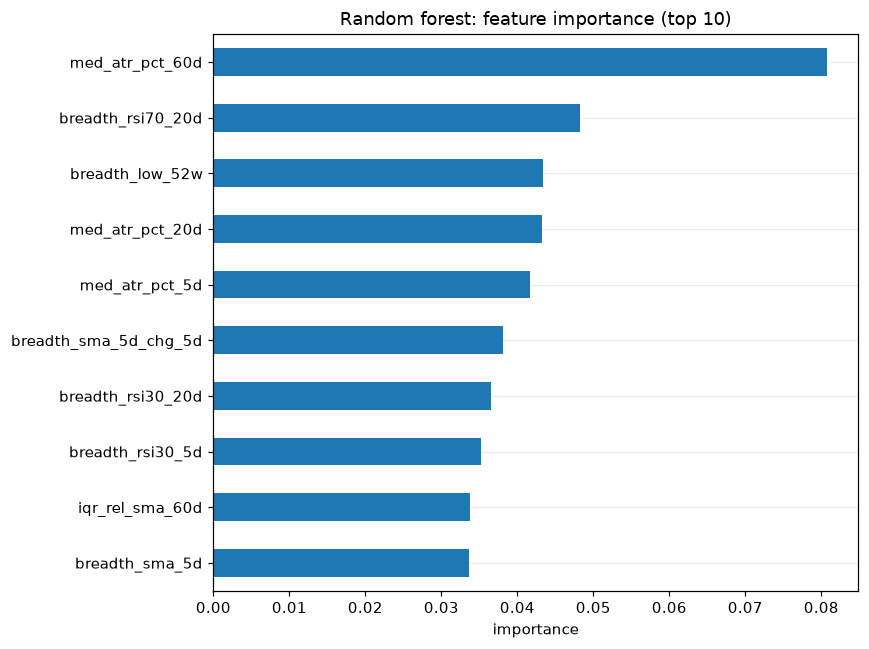

In [34]:
# random forest feature importance: averaged over the 300 trees
imp_rf = pd.Series(forest.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
imp_rf.head(10).iloc[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_title("Random forest: feature importance (top 10)")
ax.set_xlabel("importance")
ax.grid(axis="x")

fig.tight_layout()

imp_rf.head(10)

#### Logistic Regression

In [35]:
# logistic regression: probability of an up move, long when p(up) > 0.5
train = df_final[df_final.split == "train"]
valid = df_final[df_final.split == "valid"]

scaler = StandardScaler().fit(train[FEATURES])
X_train = scaler.transform(train[FEATURES])
X_valid = scaler.transform(valid[FEATURES])
y_train = (train["rr_5d"] > 0).astype(int)

logit = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logit.fit(X_train, y_train)

p_up = logit.predict_proba(X_valid)[:, 1]
sig_lr = pd.Series(p_up > 0.5, index=valid.index)

kpi_lr = add_kpi("logistic_regression", sig_lr, valid)
kpi_lr

rule,baseline,decision_tree,random_forest,logistic_regression
trades,226.000,369.000,418.000,505.000
trade_share_%,39.200,64.100,72.600,87.700
win_rate_%,59.700,59.300,59.100,59.200
avg_win_r,1.111,1.274,1.272,1.270
avg_loss_r,-1.215,-1.383,-1.321,-1.357
profit_factor_x,1.360,1.350,1.390,1.360
expectancy_r,0.174,0.194,0.211,0.198
max_open_trades,5.000,5.000,5.000,5.000
max_risk_per_trade_%,20.000,20.000,20.000,20.000
leverage_x,1.000,1.000,1.000,1.000


## Evaluation

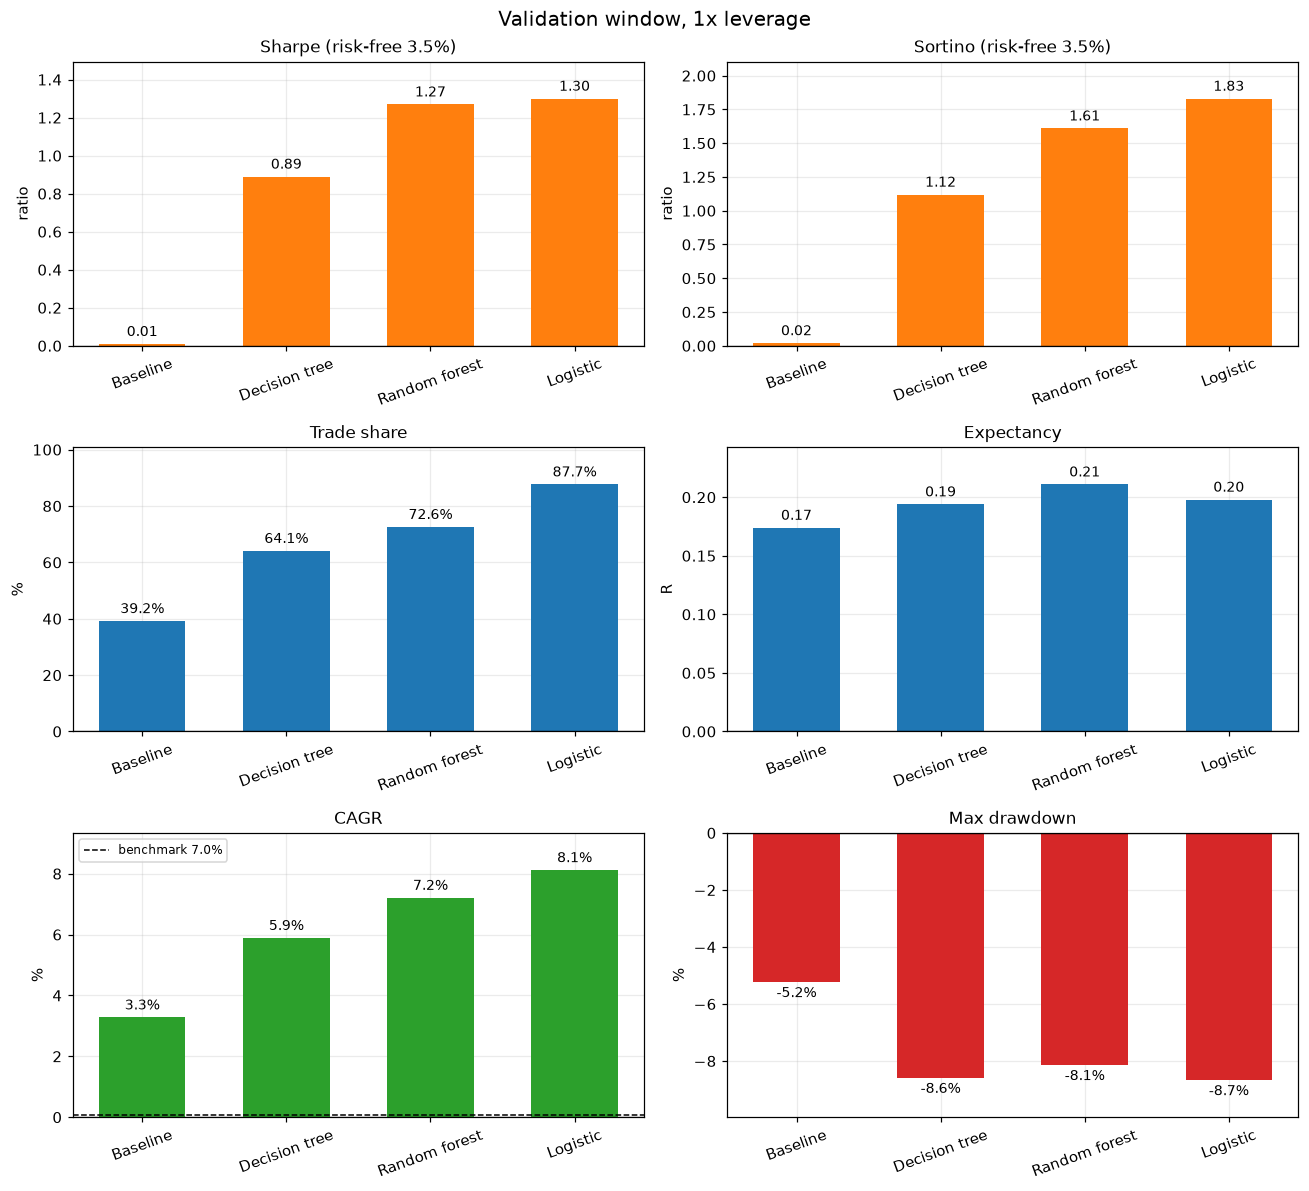

In [36]:
# headline KPIs, one panel each, same order and colours everywhere
kpi_view = pd.DataFrame(list(KPI_HISTORY.values())).set_index("rule")

order = ["baseline", "decision_tree", "random_forest", "logistic_regression"]
labels = {"baseline": "Baseline", "decision_tree": "Decision tree",
          "random_forest": "Random forest", "logistic_regression": "Logistic"}
kpi_view = kpi_view.reindex([m for m in order if m in kpi_view.index])
names = [labels[m] for m in kpi_view.index]

panels = [
    ("sharpe",         f"Sharpe (risk-free {RISK_FREE_RATE:.1%})", "ratio", "tab:orange"),
    ("sortino",        f"Sortino (risk-free {RISK_FREE_RATE:.1%})", "ratio", "tab:orange"),
    ("trade_share_%",  "Trade share",                              "%",     "tab:blue"),
    ("expectancy_r",   "Expectancy",                               "R",     "tab:blue"),
    ("cagr_%",         "CAGR",                                     "%",     "tab:green"),
    ("max_drawdown_%", "Max drawdown",                             "%",     "tab:red"),
]

fig, axes = plt.subplots(3, 2, figsize=(12, 11))

for ax_m, (col, label, unit, color) in zip(axes.ravel(), panels):
    vals = kpi_view[col]
    ax_m.bar(names, vals, color=color, width=0.6)
    ax_m.axhline(0, color="black", lw=0.8)
    ax_m.set_title(label, fontsize=11)
    ax_m.set_ylabel(unit)
    ax_m.grid(axis="y", alpha=0.25)
    ax_m.set_axisbelow(True)
    ax_m.tick_params(axis="x", rotation=20)

    for bar, v in zip(ax_m.patches, vals):
        text = f"{v:.1f}%" if unit == "%" else f"{v:.2f}"
        ax_m.annotate(text, (bar.get_x() + bar.get_width() / 2, v),
                      ha="center", va="bottom" if v >= 0 else "top",
                      fontsize=9, xytext=(0, 3 if v >= 0 else -3),
                      textcoords="offset points")

    ax_m.margins(y=0.15)

cagr_ax = axes.ravel()[4]
cagr_ax.axhline(BENCHMARK_CAGR, color="black", ls="--", lw=1,
                label=f"benchmark {BENCHMARK_CAGR:.1%}")
cagr_ax.legend(loc="upper left", fontsize=8)

fig.suptitle("Validation window, 1x leverage", fontsize=13)
fig.tight_layout()

# saved for the README
from pathlib import Path
Path("docs").mkdir(exist_ok=True)
fig.savefig("docs/validation_kpis.png", dpi=150, bbox_inches="tight")

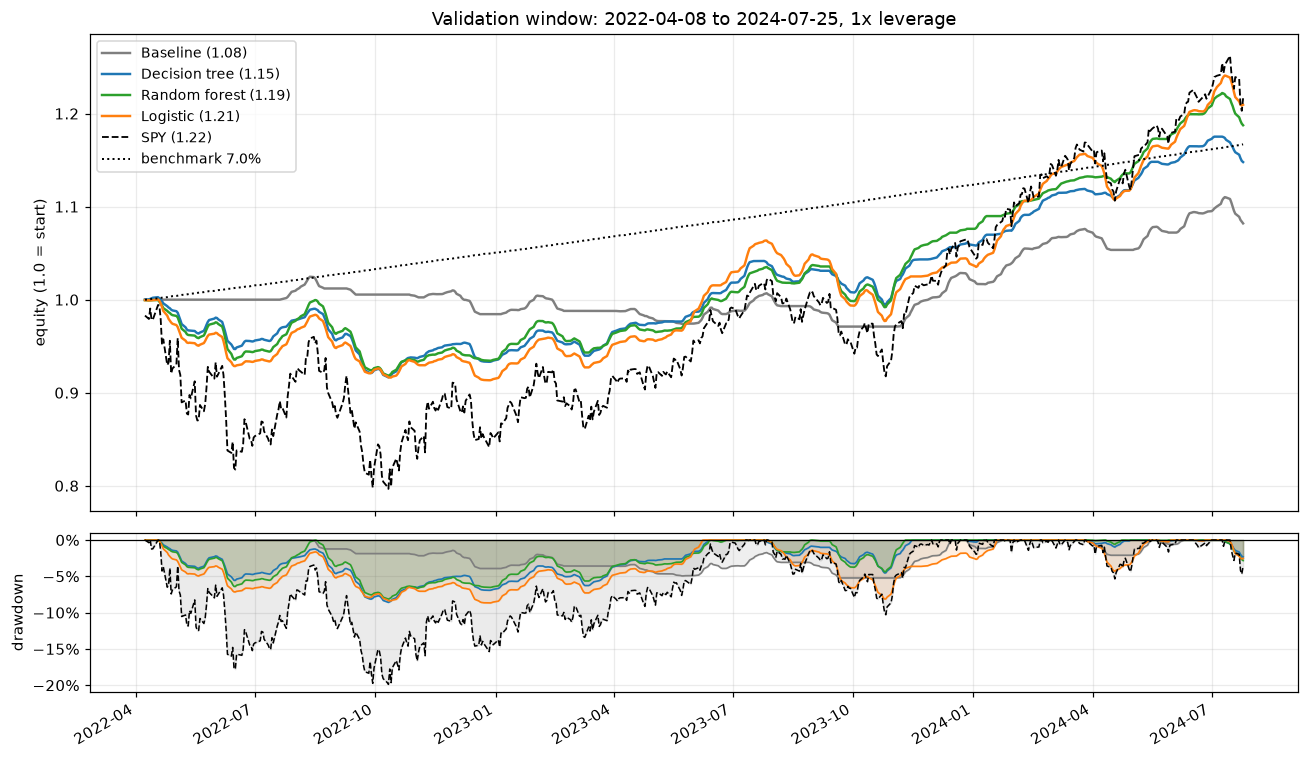

In [37]:
# equity and drawdown on the validation window, one pair per reported model
COLORS = {"baseline": "tab:gray", "decision_tree": "tab:blue",
          "random_forest": "tab:green", "logistic_regression": "tab:orange"}
LABELS = {"baseline": "Baseline", "decision_tree": "Decision tree",
          "random_forest": "Random forest", "logistic_regression": "Logistic"}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

for name, r in RETURNS.items():
    eq = (1 + r).cumprod()
    c = COLORS.get(name, "tab:purple")
    ax1.plot(eq.index, eq, lw=1.6, color=c,
             label=f"{LABELS.get(name, name)} ({eq.iloc[-1]:.2f})")
    dd = eq / eq.cummax() - 1
    ax2.plot(eq.index, dd, lw=1.1, color=c)
    ax2.fill_between(eq.index, dd, 0, color=c, alpha=0.12)

# SPY buy & hold and its drawdown, for context only
spy_daily = df_final.loc[valid.index, "chg_1d"] / 100
spy_equity = (1 + spy_daily).cumprod()
ax1.plot(valid.index, spy_equity, color="black", ls="--", lw=1.2,
         label=f"SPY ({spy_equity.iloc[-1]:.2f})")
spy_dd = spy_equity / spy_equity.cummax() - 1
ax2.plot(valid.index, spy_dd, color="black", ls="--", lw=1)
ax2.fill_between(valid.index, spy_dd, 0, color="black", alpha=0.08)

# the bar to clear
rf_curve = (1 + BENCHMARK_CAGR) ** (np.arange(len(valid)) / 252)
ax1.plot(valid.index, rf_curve, color="black", ls=":", lw=1.3,
         label=f"benchmark {BENCHMARK_CAGR:.1%}")

ax1.set_ylabel("equity (1.0 = start)")
ax1.set_title(f"Validation window: {valid.index.min().date()} to {valid.index.max().date()}, "
              f"{LEVERAGE:g}x leverage")
ax1.grid(alpha=0.25)
ax1.legend(loc="upper left", fontsize=9)

ax2.set_ylabel("drawdown")
ax2.axhline(0, color="black", lw=0.8)
ax2.grid(alpha=0.25)
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

fig.autofmt_xdate()
fig.tight_layout()

Path("docs").mkdir(exist_ok=True)
fig.savefig("docs/validation_equity.png", dpi=150, bbox_inches="tight")

### Preferred Model: Random Forest

- **Lowest open exposure for the return:** 72.6% of days in the market, against 87.7% for logistic and 64.1% for decision tree.
- **Highest expectancy:** 0.21R per long day, ahead of the tree (0.19) and logistic (0.20).
- **Drawdown no worse:** -8.1%, versus -8.5% for both the tree and logistic.
- **Logistic is close to buy-and-hold:** it is long almost 90% of the time, so its higher CAGR (8.3% vs 7.4%) comes from exposure or churn, not from picking better days.
- **Risk-adjusted:** Sharpe 1.33 against 1.36 for logistic; not that far for a much lower exposure & open risk.
- **Outperforms benchmark:** Beat my choice benchmark 7% gross risk free interest income (and SPY at 1x leverage).

The forest earns its place by being in the market three days in four while still producing the best per-day edge.

In [38]:
# final model: refit on train + validation, evaluated once on test
full_train = df_final[df_final.split != "test"]
test = df_final[df_final.split == "test"]

final_depth = int(best_rf["rule"].split("_d")[1].split("_")[0])
final_leaf = int(best_rf["rule"].split("_l")[1])
print(f"refit: depth={final_depth} leaf={final_leaf} on {len(full_train)} rows")

final_rf = RandomForestRegressor(n_estimators=300, max_depth=final_depth, min_samples_leaf=final_leaf,
                                 max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)
final_rf.fit(full_train[FEATURES], full_train["rr_5d"])

sig_test = pd.Series(final_rf.predict(test[FEATURES]) > 0, index=test.index)

final_row = kpi_row("random_forest_final", sig_test, test)
trial_row = dict(KPI_HISTORY["random_forest"], rule="random_forest_trial")

kpi_final = pd.DataFrame([trial_row, final_row]).set_index("rule").T
kpi_final

refit: depth=8 leaf=10 on 2304 rows


rule,random_forest_trial,random_forest_final
trades,418.000,523.000
trade_share_%,72.600,90.800
win_rate_%,59.100,57.600
avg_win_r,1.272,1.263
avg_loss_r,-1.321,-1.319
profit_factor_x,1.390,1.300
expectancy_r,0.211,0.167
max_open_trades,5.000,5.000
max_risk_per_trade_%,20.000,20.000
leverage_x,1.000,1.000


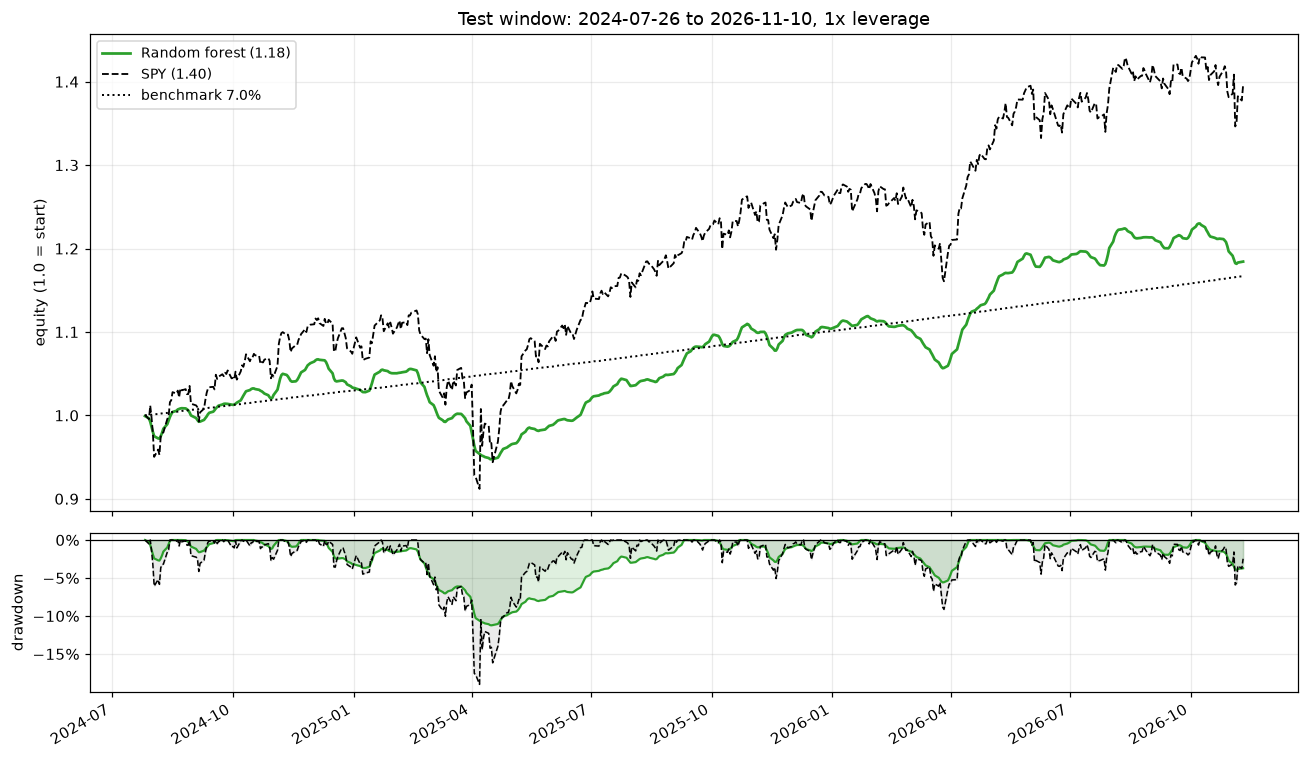

In [39]:
# final model: equity and drawdown on the test window, against SPY and the benchmark
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

# final model
r_final = RETURNS["random_forest_final"]
eq_final = (1 + r_final).cumprod()
ax1.plot(eq_final.index, eq_final, lw=1.8, color="tab:green",
         label=f"Random forest ({eq_final.iloc[-1]:.2f})")
dd_final = eq_final / eq_final.cummax() - 1
ax2.plot(eq_final.index, dd_final, lw=1.4, color="tab:green")
ax2.fill_between(eq_final.index, dd_final, 0, color="tab:green", alpha=0.15)

# SPY buy & hold
spy_test = df_final.loc[test.index, "chg_1d"] / 100
spy_equity = (1 + spy_test).cumprod()
ax1.plot(test.index, spy_equity, color="black", ls="--", lw=1.2,
         label=f"SPY ({spy_equity.iloc[-1]:.2f})")
spy_dd = spy_equity / spy_equity.cummax() - 1
ax2.plot(test.index, spy_dd, color="black", ls="--", lw=1)
ax2.fill_between(test.index, spy_dd, 0, color="black", alpha=0.08)

# the bar to clear
bench_curve = (1 + BENCHMARK_CAGR) ** (np.arange(len(test)) / 252)
ax1.plot(test.index, bench_curve, color="black", ls=":", lw=1.3,
         label=f"benchmark {BENCHMARK_CAGR:.1%}")

ax1.set_ylabel("equity (1.0 = start)")
ax1.set_title(f"Test window: {test.index.min().date()} to {test.index.max().date()}, "
              f"{LEVERAGE:g}x leverage")
ax1.grid(alpha=0.25)
ax1.legend(loc="upper left", fontsize=9)

ax2.set_ylabel("drawdown")
ax2.axhline(0, color="black", lw=0.8)
ax2.grid(alpha=0.25)
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

fig.autofmt_xdate()
fig.tight_layout()

Path("docs").mkdir(exist_ok=True)
fig.savefig("docs/test_equity.png", dpi=150, bbox_inches="tight")

In [ ]:
# export the results the Streamlit app reads (no refit, no data download needed)
import json

def clean(row):
    return {k: (round(float(v), 4) if isinstance(v, (int, float, np.floating)) else str(v))
            for k, v in row.items()}

art = {
    "window": {
        "validation": [str(valid.index.min().date()), str(valid.index.max().date())],
        "test": [str(test.index.min().date()), str(test.index.max().date())],
    },
    "validation": [clean(r) for r in kpi_view.reset_index().to_dict("records")],
    "test": clean(dict(final_row, rule="random_forest")),
    "curve": {
        "dates": [d.strftime("%Y-%m-%d") for d in test.index],
        "model": [round(float(v), 6) for v in eq_final],
        "spy": [round(float(v), 6) for v in spy_equity],
        "benchmark": [round(float(v), 6) for v in bench_curve],
    },
    "importance": {
        "random_forest": [{"feature": f, "value": round(float(v), 4)} for f, v in imp_rf.head(10).items()],
        "decision_tree": [{"feature": f, "value": round(float(v), 4)} for f, v in imp_dt.head(10).items()],
    },
    "coverage": {
        "years": [d.year for d in cov_y.index],
        "names": [round(float(v), 2) for v in cov_y["coverage_names"]],
        "weight": [round(float(v), 2) for v in cov_y["coverage_weight"]],
    },
    "settings": {
        "risk_free": RISK_FREE_RATE,
        "benchmark_cagr": BENCHMARK_CAGR,
        "leverage": LEVERAGE,
        "fee_per_trade_r": FEE_PER_TRADE_R,
    },
}

Path("docs").mkdir(exist_ok=True)
Path("docs/results.json").write_text(json.dumps(art, indent=1), encoding="utf-8")
print("artifacts ->", Path("docs/results.json").stat().st_size, "bytes")

## Interpretation

- **Out-of-sample performance degraded:** Trial expectancy 0.211R fell to 0.167R on test, drawdown grew from -8.1% to -11.2%, and Sharpe from 1.27 to 1.06.
- **The model did not protect capital:** Through the 2025 and 2026 retracements it did not cut losses, and it recovered more slowly than the index afterwards.
- **It is not only a strong-market artefact:** Being long 90.8% of the test window explains part of the return, but flat days averaged 0.248R against 0.167R when long - the timing was off.
- **Coverage is a real limitation:** Survivorship bias cuts both ways: names lost to delisting and acquisition are missing from the breadth readings, and the earlier coverage chart shows how thin the early years are.
- **Disappointing returns:** Slightly above a bond interest while carrying equity risk, with no leverage headroom left, does not justify the effort or the risk.
- **A 90-95% weight filter might improve the test**, but choosing it after seeing the result would be curve-fitting, so I am intentionally stopping here.

## What Might Improve It

1. **Better coverage** - more historical constituents and prices, especially pre-2019, to widen the window and reduce survivorship bias.
2. **Other horizons** - 20-day and 60-day targets, where breadth signals are more likely to carry information than at 5 days.
3. **Other models** - gradient boosting (XGBoost/LightGBM), and a classification target with probability-based sizing instead of fixed exposure.
4. **Regime conditioning** - trade breadth signals only when volatility or trend regimes make participation meaningful.
5. **Point-in-time sector and fundamentals** - sector breadth and earnings data, if a reliable historical source can be licensed.